<center><h1>Keehan_Alyssa_HW6</h1></center>

Name: Alyssa Keehan
<br>
Github Username: akeehan56
<br>
GitHub Links: [Class Repo](https://github.com/akeehan56/DSCI552) | [HW5](https://github.com/akeehan56/DSCI552/tree/main/HW6)
<br>
Email: akeehan@usc.edu
<br>
USC ID: 3429542433

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,roc_curve,RocCurveDisplay,
                             roc_auc_score,accuracy_score,classification_report,balanced_accuracy_score,
                             average_precision_score,precision_score,recall_score)
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [2]:
data_dir = next(
    (p for p in [Path.cwd() / "HW6/data", Path.cwd() / "data",
                 Path.cwd().parent / "HW6/data", Path.cwd().parent / "data"]
     if (p / "aps_failure_training_set.csv").exists()),
    Path("../data")
)

train_df = pd.read_csv(data_dir / "aps_failure_training_set.csv", skiprows=20, na_values=["na"])
test_df = pd.read_csv(data_dir / "aps_failure_test_set.csv", skiprows=20, na_values=["na"])
X_train, y_train = train_df.drop(columns="class"), train_df["class"].map({"neg": 0, "pos": 1})
X_test, y_test = test_df.drop(columns="class"), test_df["class"].map({"neg": 0, "pos": 1})

print("Train:", X_train.shape, "Test:", X_test.shape)
print(train_df["class"].value_counts())

Train: (60000, 170) Test: (16000, 170)
class
neg    59000
pos     1000
Name: count, dtype: int64


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [3]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train),columns=X_train.columns,index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test),columns=X_test.columns,index=X_test.index)

**Answer:**

1. **Median Imputation** fills each missing value with the median of that feature, calculated from the training data. The APS dataset contains numeric sensor features, so this is a simple and practical choice. Sensor readings can be skewed or contain extreme values; the median is less affected by those values than the mean. 
2. **KNN Imputation** fills a missing value using values from the most similar rows, called its nearest neighbors. For a numeric feature, it typically uses an average of that feature’s observed values among those neighbors; some versions give more weight to closer neighbors.

I chose median imputation as my main method because the APS dataset contains numeric sensor features, and the median is less affected by skewed values and outliers than the mean. It is also efficient for a dataset with many features.

Sources:
1. ITU Online Editorial Team. (2026, October 21). Practical techniques for handling missing data in large datasets. ITU Online IT Training. https://www.ituonline.com/blogs/practical-techniques-for-handling-missing-data-in-large-datasets/

#### (ii) Calculate the coefficient of variation

In [4]:
n_top = int(np.floor(np.sqrt(X_train_imputed.shape[1])))
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
cv_table = cv.rename("CV").to_frame().sort_values("CV", ascending=False)
print(cv_table.head(n_top))

                CV
cf_000  244.887517
co_000  244.507385
ad_000  244.322816
cs_009  237.930554
dh_000  123.216097
dj_000  117.494225
ag_000   92.917755
as_000   87.332500
ay_009   84.733735
ak_000   80.424975
az_009   77.838544
ch_000   77.453857
au_000   68.882751


In [5]:
top_features = cv_table.head(n_top).index.tolist()
(X_train_imputed[top_features].agg(["mean", "std", "min", "median", "max"]).T.round(2).style.format("{:.2f}"))

,mean,std,min,median,max
cf_000,143107.53,35045248.64,0.00,2.00,8584297736.00
co_000,143330.02,35045247.84,0.00,8.00,8584297742.00
ad_000,143438.29,35045247.41,0.00,126.00,8584297742.00
cs_009,770.51,183327.80,0.00,0.00,44902992.00
dh_000,4392.64,541244.06,0.00,0.00,124700880.00
dj_000,37.27,4379.17,0.00,0.00,726750.00
ag_000,219.16,20363.64,0.00,0.00,3376892.00
as_000,125.41,10952.19,0.00,0.00,1655240.00
ay_009,1149.62,97411.56,0.00,0.00,18824656.00
ak_000,907.66,72998.59,0.00,0.00,10444924.00


**Answer:**

The highest-CV features have large variability relative to their means. Several CV values are extremely high, which may be due to means close to zero. These rankings help identify features to visualize, but CV alone does not show whether a feature predicts the class.

#### (iii) Plot a correlation matrix

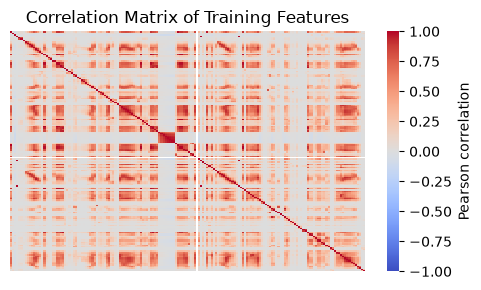

In [6]:
corr_matrix = X_train_imputed.corr(method="pearson")
plt.figure(figsize=(5, 3))
sns.heatmap(corr_matrix, cmap="coolwarm",center=0,vmin=-1,vmax=1,
            xticklabels=False,yticklabels=False,cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Matrix of Training Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Selected 13 features:
cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64


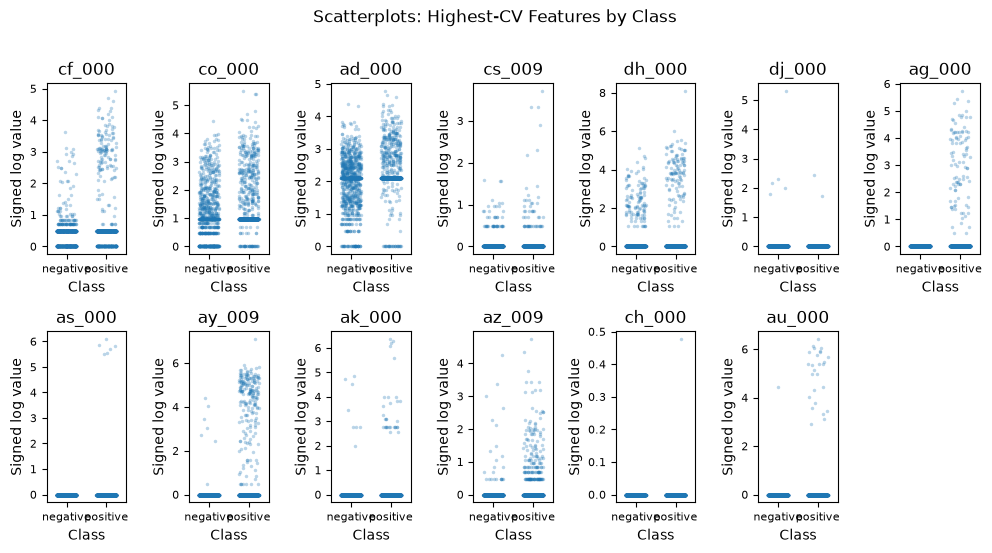

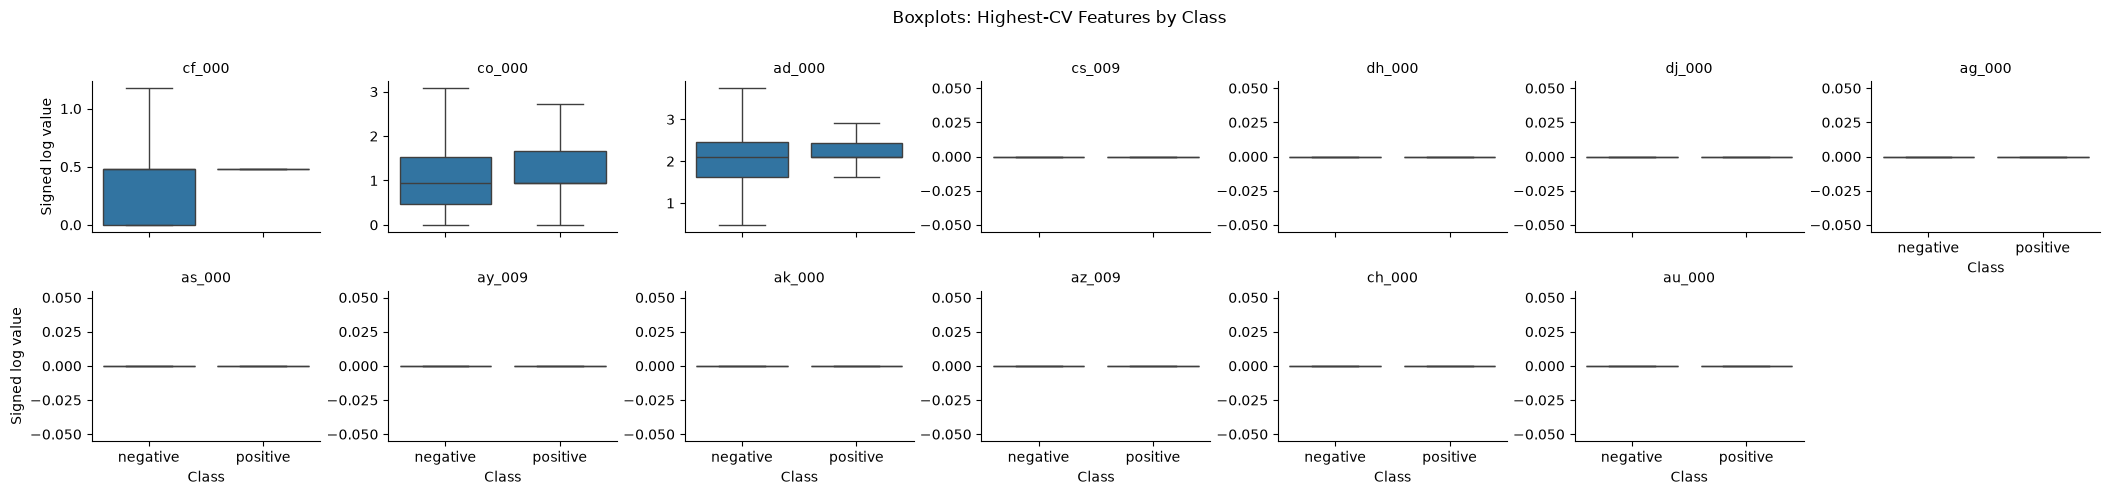

In [7]:
cv = (X_train_imputed.std(ddof=1) / X_train_imputed.mean()).replace([np.inf, -np.inf], np.nan).dropna()
n_top = int(np.floor(np.sqrt(X_train_imputed.shape[1])))
top_features = cv.nlargest(n_top).index.tolist()
print(f"Selected {n_top} features:\n{cv.loc[top_features]}")
y = pd.Series(np.asarray(y_train).ravel(), index=X_train_imputed.index, name="class_label").replace(
    {0: "negative", 1: "positive", "neg": "negative", "pos": "positive"}
)
plot_df = X_train_imputed[top_features].assign(class_label=y).melt(
    id_vars="class_label", var_name="feature", value_name="value"
)
plot_df["log_value"] = np.sign(plot_df["value"]) * np.log10(1 + np.abs(plot_df["value"]))
scatter_sample = pd.concat(
    [g.sample(min(len(g), 1000), random_state=42) for _, g in plot_df.groupby(["feature", "class_label"])],
    ignore_index=True
)
ncols = 7
fig, axes = plt.subplots(int(np.ceil(n_top / ncols)), ncols, figsize=(10, 2.8 * np.ceil(n_top / ncols)), squeeze=False)
axes = axes.ravel()
for ax, feature in zip(axes, top_features):
    sns.stripplot(data=scatter_sample[scatter_sample["feature"] == feature], x="class_label", y="log_value",
                  jitter=0.25, alpha=0.3, size=2.5, ax=ax)
    ax.set(title=feature, xlabel="Class", ylabel="Signed log value")
    ax.tick_params(axis="both", labelsize=8)
for ax in axes[n_top:]: ax.remove()
fig.suptitle("Scatterplots: Highest-CV Features by Class")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

g = sns.catplot(data=plot_df, x="class_label", y="log_value", col="feature", col_wrap=7, kind="box",sharey=False, showfliers=False, height=2.5, aspect=1.2)
g.set_axis_labels("Class", "Signed log value")
g.set_titles("{col_name}")
g.fig.suptitle("Boxplots: Highest-CV Features by Class")
g.fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Answer:**

*Can we conclude significance from the scatterplots?* No. The plots can suggest possible differences, but they cannot establish statistical significance or whether a feature will improve a model. The features were chosen for high CV, which measures variability relative to the mean, not class separation.

#### (v) Is this data set imbalanced?

In [8]:
class_labels = train_df["class"].astype(str).str.strip().str.lower()
print("Labels found:", class_labels.unique())
class_counts = class_labels.value_counts().reindex(
    ["neg", "pos"],
    fill_value=0
)
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / class_counts.sum() * 100).round(2)
})
print(class_summary)
print(f'Negative-to-positive ratio: {class_counts["neg"] / class_counts["pos"]:.0f}:1')

Labels found: <ArrowStringArray>
['neg', 'pos']
Length: 2, dtype: str
       Count  Percentage
class                   
neg    59000       98.33
pos     1000        1.67
Negative-to-positive ratio: 59:1


**Answer:**

The training set contains 59,000 negative cases and 1,000 positive cases. This is a highly imbalanced dataset: the negative class makes up about 98.3% of the data, while the positive class makes up about 1.7%, a ratio of 59 negative cases for every positive case.

### (c) Train a random forest

#### 1. fit the model

In [9]:
rf_model = RandomForestClassifier(n_estimators=500,random_state=17,oob_score=True,class_weight=None,n_jobs=-1)
rf_model.fit(X_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",17
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

#### 2. predict porbability of the classes

In [10]:
pos_label = 1
pos_index = list(rf_model.classes_).index(pos_label)
train_pred = rf_model.predict(X_train_imputed)
test_pred = rf_model.predict(X_test_imputed)
train_prob = rf_model.predict_proba(X_train_imputed)[:, pos_index]
test_prob = rf_model.predict_proba(X_test_imputed)[:, pos_index]
train_auc = roc_auc_score(y_train == pos_label, train_prob)
test_auc = roc_auc_score(y_test == pos_label, test_prob)

#### 3. print confusion matrices

In [11]:
train_cm = confusion_matrix(y_train, train_pred, labels=[0, 1])
test_cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
print("Rows: actual [0, 1]; columns: predicted [0, 1]")
print("Training confusion matrix:\n", train_cm)
print("Test confusion matrix:\n", test_cm)

Rows: actual [0, 1]; columns: predicted [0, 1]
Training confusion matrix:
 [[59000     0]
 [    0  1000]]
Test confusion matrix:
 [[15608    17]
 [  104   271]]


#### 4. calculate OC, AUC, and misclassification for training and test sets

Train error: 0.0000 | Test error: 0.0076
Train AUC: 1.0000 | Test AUC: 0.9940
OOB error: 0.0059


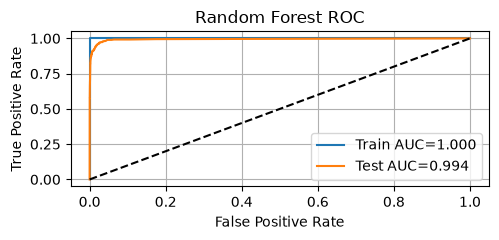

In [12]:
y_train_array, y_test_array = np.asarray(y_train).ravel(), np.asarray(y_test).ravel()
train_error, test_error = np.mean(train_pred != y_train), np.mean(test_pred != y_test)
train_auc, test_auc = roc_auc_score(y_train_array, train_prob), roc_auc_score(y_test_array, test_prob)
train_fpr, train_tpr, _ = roc_curve(y_train_array == 1, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_array == 1, test_prob)
print(f"Train error: {train_error:.4f} | Test error: {test_error:.4f}\nTrain AUC: {train_auc:.4f} | Test AUC: {test_auc:.4f}\nOOB error: {1 - rf_model.oob_score_:.4f}")
plt.figure(figsize=(5, 2.5)); plt.plot(train_fpr, train_tpr, label=f"Train AUC={train_auc:.3f}"); plt.plot(test_fpr, test_tpr, label=f"Test AUC={test_auc:.3f}"); plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Random Forest ROC"); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

**Answer:**

The training misclassification rate was 0.0000, with an AUC of 1.0000. The perfect training results are less informative because they were calculated on the data used to fit the forest. On the test set, the misclassification rate was 0.0076 (0.76%), and the AUC was 0.9940. The OOB error estimate was 0.0059 (0.59%), which is close to the test error of 0.76%. This suggests the OOB estimate was a reasonable approximation of the test error.

### (d) Research class imbalance in random forest

#### 1. Keep the 1c settings and change only the class weighting

In [13]:
balanced_rf = clone(rf_model).set_params(
    class_weight="balanced_subsample"
)
balanced_rf.fit(X_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",17
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for

#### 2. Find the probability column for the positive class

In [14]:
positive_label = 1
positive_col = list(balanced_rf.classes_).index(positive_label)
train_pred = balanced_rf.predict(X_train_imputed)
test_pred = balanced_rf.predict(X_test_imputed)
train_prob = balanced_rf.predict_proba(X_train_imputed)[:, positive_col]
test_prob = balanced_rf.predict_proba(X_test_imputed)[:, positive_col]

#### 3. Present Results

In [15]:
print(f"Training misclassification rate: {1 - accuracy_score(y_train, train_pred):.4f}")
print(f"Test misclassification rate:     {1 - accuracy_score(y_test, test_pred):.4f}")
print(f"Training AUC: {roc_auc_score(y_train, train_prob):.4f}")
print(f"Test AUC:     {roc_auc_score(y_test, test_prob):.4f}")
print(f"Training balanced accuracy: {balanced_accuracy_score(y_train, train_pred):.4f}")
print(f"Test balanced accuracy:     {balanced_accuracy_score(y_test, test_pred):.4f}")
print(f"Test positive-class precision: {precision_score(y_test, test_pred, pos_label=positive_label):.4f}")
print(f"Test positive-class recall:    {recall_score(y_test, test_pred, pos_label=positive_label):.4f}")
print(f"Test average precision:        {average_precision_score(y_test, test_prob, pos_label=positive_label):.4f}")
print("Test confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))
print(f"OOB error estimate: {1 - balanced_rf.oob_score_:.4f}")

Training misclassification rate: 0.0000
Test misclassification rate:     0.0108
Training AUC: 1.0000
Test AUC:     0.9945
Training balanced accuracy: 1.0000
Test balanced accuracy:     0.7902
Test positive-class precision: 0.9356
Test positive-class recall:    0.5813
Test average precision:        0.8850
Test confusion matrix (rows = actual, columns = predicted):
[[15610    15]
 [  157   218]]
OOB error estimate: 0.0072


**Answer:**

I addressed class imbalance by setting class_weight="balanced_subsample", which adjusts class weights for each tree’s bootstrap sample. Compared with the original model, the weighted model had a slightly higher test misclassification rate (0.0108 vs. 0.0076), a slightly higher test AUC (0.9945 vs. 0.9940), and a higher OOB error estimate (0.0072 vs. 0.0059). Across these three metrics, the weighted model performed slightly worse than the original model.

### (e) XGBoost and Model Trees

#### 1. Set Up Model + Cross validate

In [16]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=17)
xgb_model = XGBClassifier(objective="binary:logistic",eval_metric="logloss",tree_method="hist",n_estimators=200,
                          learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,random_state=17,n_jobs=-1)
param_grid = {
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}
grid_search = GridSearchCV(estimator=xgb_model,param_grid=param_grid,scoring="accuracy",cv=cv,refit=True,n_jobs=1,verbose=1)

#### 2. fit model and report performance

In [17]:
grid_search.fit(X_train_imputed, y_train)
best_model = grid_search.best_estimator_
cv_error = 1 - grid_search.best_score_
print(f"Best alpha (reg_alpha): {grid_search.best_params_['reg_alpha']}")
print(f"5-fold CV misclassification rate: {cv_error:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best alpha (reg_alpha): 0.1
5-fold CV misclassification rate: 0.0064


#### 3. Calculate Training and Test Set predicitons and errors

In [18]:
class_names = [0, 1]
y_train_pred = best_model.predict(X_train_imputed)
y_test_pred = best_model.predict(X_test_imputed)
y_train_prob = best_model.predict_proba(X_train_imputed)[:, 1]
y_test_prob = best_model.predict_proba(X_test_imputed)[:, 1]
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
print(f"Training misclassification rate: {train_error:.4f}")
print(f"Test misclassification rate:     {test_error:.4f}")

The history saving thread hit an unexpected error (OperationalError('unable to open database file')).History will not be written to the database.
Training misclassification rate: 0.0026
Test misclassification rate:     0.0079


#### 4. Display Training and Test Confusion matrices

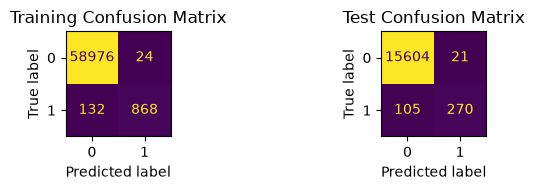

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2))
ConfusionMatrixDisplay(
    confusion_matrix(y_train, y_train_pred, labels=[0, 1]),display_labels=class_names).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Training Confusion Matrix")
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_test_pred, labels=[0, 1]),display_labels=class_names).plot(ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

#### 5. calculate AUC and ROC curves

Training AUC: 0.9986
Test AUC:     0.9965


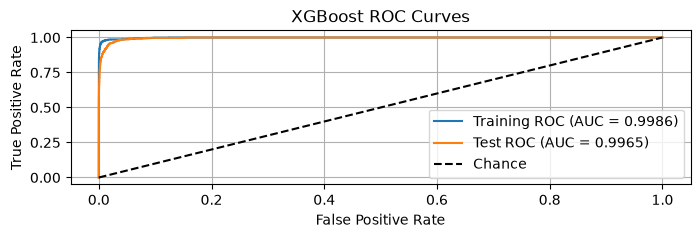

In [20]:
train_auc = roc_auc_score(y_train, y_train_prob)
test_auc = roc_auc_score(y_test, y_test_prob)
train_fpr, train_tpr, _ = roc_curve(y_train, y_train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, y_test_prob)
print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC:     {test_auc:.4f}")
plt.figure(figsize=(8, 2))
plt.plot(train_fpr, train_tpr, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(test_fpr, test_tpr, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

**Answer:**

I fit an XGBoost classifier without class-imbalance compensation and used 5-fold cross-validation to select reg_alpha; the best value was 0. The cross-validation misclassification rate was 0.0064, compared with 0.0079 on the test set, and the AUC was 0.9986 for training and 0.9965 for testing. On the test set, the model correctly identified 270 of 375 positive cases and missed 105, while producing 21 false positives. The similar test and cross-validation errors and high test AUC indicate strong overall performance, though some positive cases were still missed.

### (f) Use SMOTE to pre-process your data

#### 1. set up CV and XG Boost classifer

In [21]:
cv_splitter = StratifiedKFold(n_splits=5,shuffle=True,random_state=17)
xgb_model = XGBClassifier(objective="binary:logistic",eval_metric="logloss",tree_method="hist",n_estimators=200,
                          learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,random_state=42,n_jobs=-1)
alpha_grid = {
    "xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}

#### 2. Set up and fit uncompensated model

In [23]:
uncompensated_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("xgb", xgb_model)
])
uncompensated_search = GridSearchCV(estimator=uncompensated_pipeline,param_grid=alpha_grid,
                                    scoring="accuracy",cv=cv_splitter,refit=True,n_jobs=1)
uncompensated_search.fit(X_train_imputed, y_train)
print("Uncompensated best parameters:", uncompensated_search.best_params_)
print("Uncompensated best CV accuracy:", uncompensated_search.best_score_)

Uncompensated best parameters: {'xgb__reg_alpha': 0.1}
Uncompensated best CV accuracy: 0.9936


#### 3. Set up and fit SMOTE model

In [24]:
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", xgb_model)
])
smote_search = GridSearchCV(estimator=smote_pipeline,param_grid=alpha_grid,scoring="accuracy",cv=cv_splitter,refit=True,n_jobs=1)
smote_search.fit(X_train_imputed, y_train)
print("SMOTE best parameters:", smote_search.best_params_)
print("SMOTE best CV accuracy:", smote_search.best_score_)

SMOTE best parameters: {'xgb__reg_alpha': 0.1}
SMOTE best CV accuracy: 0.9858333333333332


#### 4. Compare Models on Untouched Test Set

In [25]:
def evaluate_model(name, search):
    model = search.best_estimator_
    predictions = model.predict(X_test_imputed)
    probabilities = model.predict_proba(X_test_imputed)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    return {
        "Model": name,"Best alpha": search.best_params_["xgb__reg_alpha"],
        "CV accuracy": search.best_score_,"Test error": 1 - accuracy_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities),"Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),"Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }
comparison = pd.DataFrame([evaluate_model("Uncompensated", uncompensated_search),evaluate_model("SMOTE", smote_search)]).set_index("Model").round(4)
comparison

,Best alpha,CV accuracy,Test error,ROC AUC,Precision,Recall,Balanced accuracy,TN,FP,FN,TP
Model,,,,,,,,,,,
Uncompensated,0.1,0.9936,0.0074,0.9962,0.9267,0.7413,0.8700,15603,22,97,278
SMOTE,0.1,0.9858,0.0139,0.9930,0.6479,0.8880,0.9382,15444,181,42,333


**Answer:**

The uncompensated model performed better on overall test misclassification rate (0.0074 vs. 0.0139) and ROC AUC (0.9962 vs. 0.9930). SMOTE improved positive-case detection: recall increased from 0.7413 to 0.8880, and false negatives fell from 97 to 42. That gain came with lower precision (0.9267 to 0.6479) and more false positives (22 to 181). So SMOTE found more positive cases, while the uncompensated model made fewer overall errors.

## 2. ISLR 6.6.3 (Page 292)

### a. As we increase s from 0, the training RSS will:

**Answer:** iv. steadily decrease -> As $s$ increases, the set of allowed coefficient values grows, so the model can fit the training data at least as well as before.

### b. Repeat (a) for test RSS

**Answer:** ii. Decrease initially, and then eventually start increasing in a U shape. -> A little flexibility can improve predictions by reducing underfitting. However, with too much flexibility, the model may beign to fit noise in the training data.

### c. Repeat (a) for variance

**Answer:** iii. steadily increase -> More flexible models tend to depend more on the particular training sample, so their predictions vary more across different samples.

### d. Repeat (a) for (squared) bias

**Answer:** iv. steadily decrease -> As $s$ increases, model can then capture more of the relationship between the predictors and response, so its squared bias generally decreases. More flexibility reduces the error from the model being too simple.

### e. Repeat (a) for irreducible error

**Answer:** v. remain constant -> This error comes from randomness in the response and does not depend on $s$.

## 3. ISLR 6.6.5 (Page 293)

#### a. 
**Answer:** Since $x_{11}=x_{12}$, $x_{21}=x_{22}=-x_{11}$, $y_2=-y_1$, and the intercept is zero, the fitted values are $\hat{y}_1=x_{11}(\beta_1+\beta_2)$ and $\hat{y}_2=-x_{11}(\beta_1+\beta_2)$. The ridge optimization problem is therefore

$$
\min_{\beta_1,\beta_2}
\left[
2\left(y_1-x_{11}(\beta_1+\beta_2)\right)^2
+\lambda(\beta_1^2+\beta_2^2)
\right].
$$

The RSS depends only on $\beta_1+\beta_2$.

#### b. 
**Answer:** For a fixed sum $\beta_1+\beta_2$, the fitted values and RSS stay the same. The ridge penalty is

$$
\beta_1^2+\beta_2^2
=\frac{(\beta_1+\beta_2)^2}{2}
+\frac{(\beta_1-\beta_2)^2}{2},
$$

which is minimized when $\beta_1-\beta_2=0$. Therefore, $\boxed{\hat{\beta}_1=\hat{\beta}_2}$.

#### c.
**Answer:**

The lasso uses the same residual sum of squares as ridge, but its penalty is the sum of the absolute values of the coefficients. Its optimization problem is

$$
\min_{\beta_1,\beta_2}
\left[
\left(y_1-x_{11}(\beta_1+\beta_2)\right)^2
+\left(y_2+x_{11}(\beta_1+\beta_2)\right)^2
+\lambda(|\beta_1|+|\beta_2|)
\right].
$$

Again, the RSS depends only on $\beta_1+\beta_2$. The lasso penalty determines how that sum can be divided between the two coefficients.

#### d. 
**Answer:** For a fixed sum $S=\beta_1+\beta_2$, the fitted values and RSS are fixed. The lasso penalty satisfies

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|S|,
$$

with equality when the coefficients have the same sign. Thus, if the optimal sum $S^*>0$, every pair $(t,S^*-t)$ with $0\leq t\leq S^*$ is a solution; for $S^*<0$, the same applies with both coefficients nonpositive. The lasso solutions are therefore nonunique when $S^*\neq0$. If $S^*=0$, the only minimum-penalty pair is $(0,0)$.

## 4. ISLR 8.4.5 (page 371)

In [26]:
color_classes = ['red','green']
probs = [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]
# majority
pos_counts = 0
for p in probs:
    if p >  0.5:
        pos_counts += 1
print(f"Number of probabilities leaning Red: {pos_counts}")
if pos_counts > len(probs) / 2:
    print("Majority class: Red")
else:
    print("Majority class: Green")
# avg. probability
avg_prob = np.mean(probs)
print(f"Average probability: {avg_prob:.2f}")

if avg_prob > 0.5:
    print("Majority class: Red")
else:
    print("Majority class: Green")

Number of probabilities leaning Red: 6
Majority class: Red
Average probability: 0.45
Majority class: Green


**Answer:**

**Majority Vote:** Red. Six of the ten probabilities are above 0.5

**Average Probability:** Green. The mean probability of Red is 4.5/10 = 0.45, below 0.5.

## 5. ISLR 9.7.3 (page 403)

AI Note: For this section, I used AI to build out the plots and the additional features based on my recommendations, so I didn't have to do antyhing using paper/pencil.

In [27]:
# Observations, in order
red_points = [(3, 4), (2, 2), (4, 4), (1, 4)]  # 1–4
blue_points = [(2, 1), (4, 3), (4, 1)]         # 5–7
support_vectors = [(2, 2), (4, 4), (2, 1), (4, 3)]
def plot_observations(ax, show_support_vectors=False):
    """Plot and label the seven original observations."""
    red_x, red_y = zip(*red_points)
    blue_x, blue_y = zip(*blue_points)
    ax.scatter(red_x, red_y, color="red", marker="o", s=90, label="Red")
    ax.scatter(blue_x, blue_y, color="blue", marker="s", s=90, label="Blue")
    for obs, (x1, x2) in enumerate(red_points + blue_points, start=1):
        ax.annotate(str(obs), (x1, x2), xytext=(6, 6),
                    textcoords="offset points")
    if show_support_vectors:
        sv_x, sv_y = zip(*support_vectors)
        ax.scatter(
            sv_x, sv_y,facecolors="none", edgecolors="black",marker="o", s=220, linewidths=2,label="Support vectors")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_xticks(range(1, 5))
    ax.set_yticks(range(1, 5))
    ax.set_xlim(0.5, 4.7)
    ax.set_ylim(0.5, 4.7)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.set_aspect("equal")

#### a. 

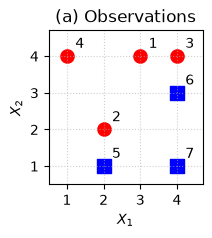

In [28]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax)
ax.set_title("(a) Observations")
plt.show()

#### b. 

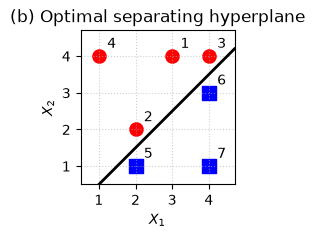

In [29]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax)

# Optimal hyperplane: X2 - X1 + 1/2 = 0
x = [0.5, 4.7]
ax.plot(x, [value - 0.5 for value in x],
        color="black", linewidth=2, label="Optimal hyperplane")

ax.set_title("(b) Optimal separating hyperplane")
plt.show()

**Answer:** The maximal margin hyperplane is $X_2-X_1+\frac{1}{2}=0$, or $X_2=X_1-\frac{1}{2}$. It separates the red observations above the line from the blue observations below it.

#### c. 

**Answer:** Classify as Red if $1-2X_1+2X_2>0$ and Blue otherwise. Thus, $\beta_0=1$, $\beta_1=-2$, and $\beta_2=2$.

#### d. 

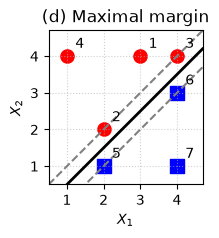

In [30]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax)

x = [0.5, 4.7]

# Optimal hyperplane: X2 = X1 - 1/2
ax.plot(x, [value - 0.5 for value in x],
        color="black", linewidth=2, label="Optimal hyperplane")

# Margin boundaries: X2 = X1 and X2 = X1 - 1
ax.plot(x, x, color="gray", linestyle="--", label="Margin boundaries")
ax.plot(x, [value - 1 for value in x],
        color="gray", linestyle="--")

ax.set_title("(d) Maximal margin")
plt.show()

**Answer:**

The margin boundaries are

$$
X_2 = X_1
\qquad\text{and}\qquad
X_2 = X_1 - 1.
$$

The maximal margin hyperplane lies halfway between them, at $X_2 = X_1 - \frac{1}{2}$. The distance from the hyperplane to either margin boundary is $\frac{1}{\sqrt{8}}$, so the total margin width is $\frac{1}{\sqrt{2}}$.

#### e. 

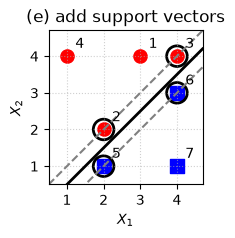

In [31]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax, show_support_vectors=True)

x = [0.5, 4.7]

# Optimal hyperplane: X2 = X1 - 1/2
ax.plot(x, [value - 0.5 for value in x],
        color="black", linewidth=2, label="Optimal hyperplane")

# Margin boundaries: X2 = X1 and X2 = X1 - 1
ax.plot(x, x, color="gray", linestyle="--", label="Margin boundaries")
ax.plot(x, [value - 1 for value in x], color="gray", linestyle="--")

ax.set_title("(e) add support vectors")
plt.show()

**Answer:**

The support vectors are observations 2 and 3 from the Red class, at $(2,2)$ and $(4,4)$, and observations 5 and 6 from the Blue class, at $(2,1)$ and $(4,3)$. These are the observations that lie on the margin boundaries.

#### f. 

**Answer:**

Observation 7, at $(4,1)$, is not a support vector and lies beyond the Blue margin boundary. A slight movement will not affect the maximal margin hyperplane as long as the observation stays on the Blue side and does not move onto or across the margin.

#### g. 

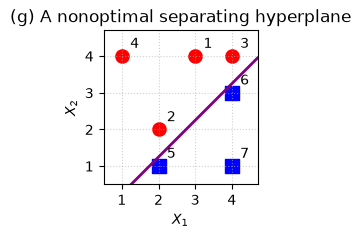

In [32]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax)

# Nonoptimal separator: X2 - X1 + 3/4 = 0
x = np.linspace(1.25, 4.7, 100)
ax.plot(x, x - 0.75, color="purple", linewidth=2, label="Nonoptimal separator")

ax.set_title("(g) A nonoptimal separating hyperplane")
plt.show()

**Answer:** One nonoptimal separating hyperplane is $X_2-X_1+\frac{3}{4}=0$. It separates the classes but is not halfway between the closest observations, so it does not maximize the margin.

#### h. 

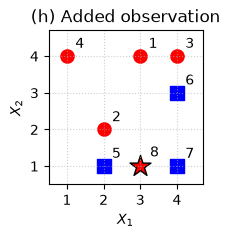

In [33]:
fig, ax = plt.subplots(figsize=(2, 2))
plot_observations(ax)

ax.scatter(3, 1, color="red", marker="*", s=250,
           edgecolors="black", label="Added Red observation (8)")
ax.annotate("8", (3, 1), xytext=(7, 7), textcoords="offset points")

ax.set_title("(h) Added observation")
plt.show()

**Answer:**

I added a Red observation at $(3,1)$. This point lies within the convex hull of the Blue observations, so the two classes are no longer separable by a straight line.